# 04 · Optimizer comparison

This notebook compares Adam, plain SGD, and SGD with momentum while keeping the CNN architecture, data split, batch size, and epoch count fixed.


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

from src.data import load_emnist
from src.preprocessing import preprocess_images
from src.models import create_cnn
from src.training import compile_model, fit_and_evaluate


I0000 00:00:1790112719.673198  118183 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790112719.728705  118183 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790112721.459966  118183 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Prepare the data

Load and normalize the images once so each optimizer sees the same inputs.


In [2]:
X_train, y_train, writers_train, X_test, y_test, writers_test = load_emnist()

X_train = preprocess_images(X_train)
X_test = preprocess_images(X_test)

## Set up optimizer runs

The learning rates are specified alongside each optimizer. Each run records its training history and test metrics for comparison.


In [3]:
optimizers = {
    "Adam": tf.keras.optimizers.Adam(learning_rate=0.001),

    "SGD": tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),

    "SGD + Momentum": tf.keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    )
}

W0000 00:00:1790112724.874269  118183 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [4]:
results = {}

for name, optimizer in optimizers.items():
    print(f"\n{'='*20} {name} {'='*20}")

    model = compile_model(create_cnn(), optimizer=optimizer)
    result = fit_and_evaluate(
        model, X_train, y_train, X_test, y_test,
        epochs=10, batch_size=128, verbose=1,
    )
    results[name] = result
    print(f"{name} test accuracy: {result['test_accuracy']:.4f}")



==================== Adam ====================
Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 31s 18ms/step - accuracy: 0.9606 - loss: 0.1336 - val_accuracy: 0.9904 - val_loss: 0.0328
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.9864 - loss: 0.0486 - val_accuracy: 0.9914 - val_loss: 0.0275
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 31s 18ms/step - accuracy: 0.9898 - loss: 0.0368 - val_accuracy: 0.9932 - val_loss: 0.0231
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 31s 18ms/step - accuracy: 0.9916 - loss: 0.0308 - val_accuracy: 0.9947 - val_loss: 0.0194
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 31s 18ms/step - accuracy: 0.9929 - loss: 0.0258 - val_accuracy: 0.9946 - val_loss: 0.0201
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 30s 18ms/step - accuracy: 0.9936 - loss: 0.0227 - val_accuracy: 0.9943 - val_loss: 0.0219
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.9942 - loss: 0.0201 - val_accuracy: 0.9948 - val_loss: 0.0203
Epoch 8/10
1688/1688 ━━━━━━━

## Compare results

Review the test metrics and validation curves. Validation curves help show how quickly each optimizer learns and whether progress levels off.


In [5]:
for name, result in results.items():
    print(
        f"{name:20s} "
        f"accuracy = {result['test_accuracy']:.4f}, "
        f"loss = {result['test_loss']:.4f}"
    )

Adam                 accuracy = 0.9954, loss = 0.0188
SGD                  accuracy = 0.9871, loss = 0.0415
SGD + Momentum       accuracy = 0.9942, loss = 0.0201


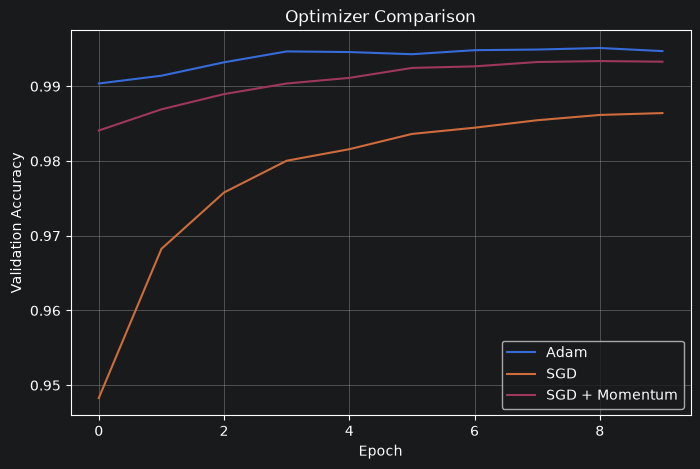

In [6]:
plt.figure(figsize=(8, 5))

for name, result in results.items():
    plt.plot(
        result["history"].history["val_accuracy"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Optimizer Comparison")
plt.legend()
plt.grid(True)
plt.show()

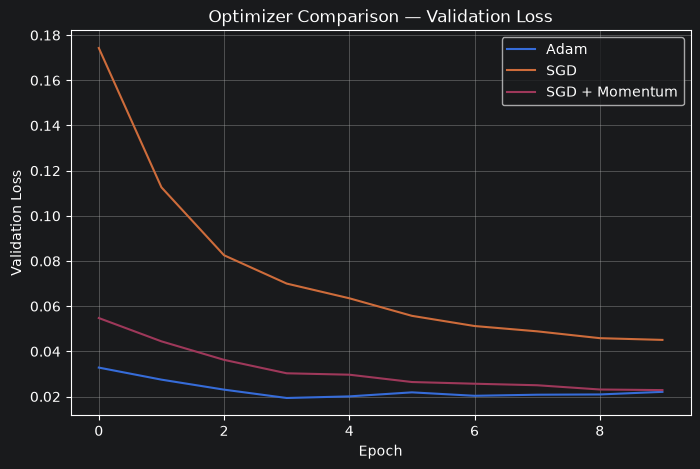

In [7]:
plt.figure(figsize=(8, 5))

for name, result in results.items():
    plt.plot(
        result["history"].history["val_loss"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Optimizer Comparison — Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## Save the summary

The final cell writes the measured test accuracy and loss to the project’s `models` folder.


In [8]:
import json

summary = {
    name: {
        "test_accuracy": float(result["test_accuracy"]),
        "test_loss": float(result["test_loss"])
    }
    for name, result in results.items()
}

with open("../models/optimizer_results.json", "w") as f:
    json.dump(summary, f, indent=4)

## Findings

In the saved run, Adam reached **99.54%** test accuracy, SGD reached **98.71%**, and SGD with momentum reached **99.42%**. Adam was highest in this run; the momentum result was close.
